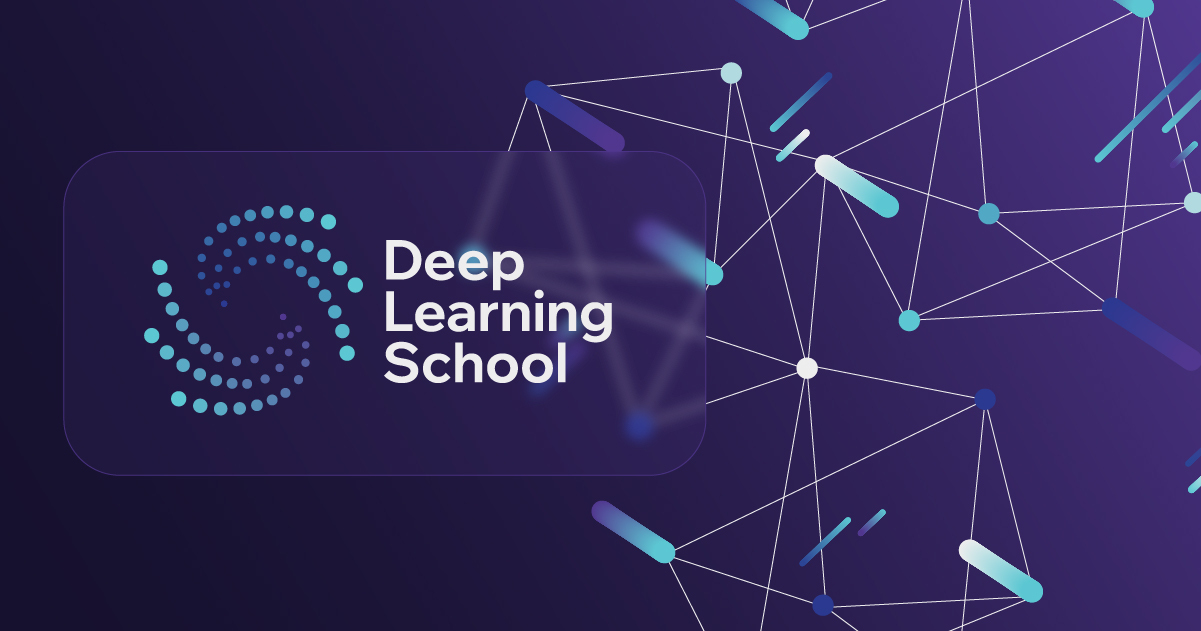

# Домашнее задание: создаём и исследуем небольшой Vision Transformer

В этом задании вы реализуете **Vision Transformer (ViT) с нуля** на PyTorch и обучите его классифицировать изображения одежды FashionMNIST. Затем исследуете три вопроса:

1. **Знает ли ViT, где должен находиться патч?** Проверим влияние перестановки патчей и позиционных эмбеддингов.
2. **Важны ли для предсказания патчи с высоким весом внимания?** Сравним маскирование по весам внимания со случайным маскированием.
3. **Что дают патчи меньшего размера?** Сравним качество классификации и измеренное время обучения.

## Что нужно реализовать

Вам предстоит выполнить TODO 1–8: свёрточные эмбеддинги патчей, multi-head attention, MLP для отдельных токенов, блок трансформера, полный классификатор ViT, attention rollout, ранжирование патчей и расчёт их количества. Кроме того, нужно ответить на вопросы к трём экспериментам, опираясь на полученные результаты.

## Система оценивания

Первая половина ноутбука — реализация ViT — в сумме дает 5 баллов. Далее три секции с тремя видами экспериментов с компонентами ViT: они дают 5, 4 и 3 балла соответственно. Вы можете выбрать, какие дополнительные секции из трех реализовать, чтобы набрать нужное вам количество баллов.

## 1. Подготовка

In [2]:
%%bash

# pip install torch==2.11.0+cu130 torchvision==0.26.0+cu130

In [3]:
import copy
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 1337

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Используем эту функцию при измерении времени обучения.
def synchronize():
    # Операции GPU асинхронны; перед измерением времени нужна синхронизация.
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()

seed_everything()
print('Устройство:', device, "| PyTorch:", torch.__version__)

Устройство: cuda | PyTorch: 2.11.0+cu130


## 2. Данные: Fashion-MNIST

Мы будем работать с датасетом [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist): это grayscale изображения размером 28×28, относящиеся к 10 категориям одежды и обуви. Мы сохраним исходное разрешение картинок, не будем их увеличивать, так как увеличение изображений добавило бы вычислений, но не новых деталей.

Из официальной обучающей выборки выделим непересекающиеся, сбалансированные по классам обучающую и валидационную подвыборки. Для воспроизводимости зафиксируем seed. Официальную тестовую выборку из 10 000 изображений оставим для итоговой оценки.

При предобработке переведём значения пикселей из `[0, 255]` в `[-1, 1]`. Аугментации использовать не будем: так результаты экспериментов с патчами будет проще интерпретировать.

Загрузим данные, разделим их на обучающую и валидационную выборки и создадим загрузчики данных:

In [4]:
CKPT_DIR = "./DLS_HW1/checkpoints"
DATA_ROOT = Path("./DLS_HW1")
EXPERIMENT_IMAGES = 100         # Валидационные примеры для перестановки и маскирования.
TRAIN_PER_CLASS = 1000
VAL_PER_CLASS = 200
NUM_CLASSES = 10

raw_train = FashionMNIST(DATA_ROOT, train=True, download=True)
raw_test = FashionMNIST(DATA_ROOT, train=False, download=True)

# Названия для графиков в исходном порядке классов Fashion-MNIST.
class_names = ['Футболка/топ', 'Брюки', 'Пуловер', 'Платье', 'Пальто', 'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']
g = torch.Generator().manual_seed(SEED)

train_indices, val_indices = [], []
assert TRAIN_PER_CLASS > 0 and VAL_PER_CLASS > 0
for label in range(NUM_CLASSES):
    ids = torch.where(raw_train.targets == label)[0]
    ids = ids[torch.randperm(len(ids), generator=g)]
    assert TRAIN_PER_CLASS + VAL_PER_CLASS <= len(ids)
    # Сначала выделяем валидацию: увеличение TRAIN_PER_CLASS не изменит её состав.
    val_indices.append(ids[:VAL_PER_CLASS])
    train_indices.append(ids[VAL_PER_CLASS:VAL_PER_CLASS + TRAIN_PER_CLASS])

train_indices = torch.cat(train_indices)
val_indices = torch.cat(val_indices)
train_indices = train_indices[torch.randperm(len(train_indices), generator=g)]
val_indices = val_indices[torch.randperm(len(val_indices), generator=g)]
assert not set(train_indices.tolist()) & set(val_indices.tolist())

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.15MB/s]


обучение / валидация / тест: 10000 2000 10000


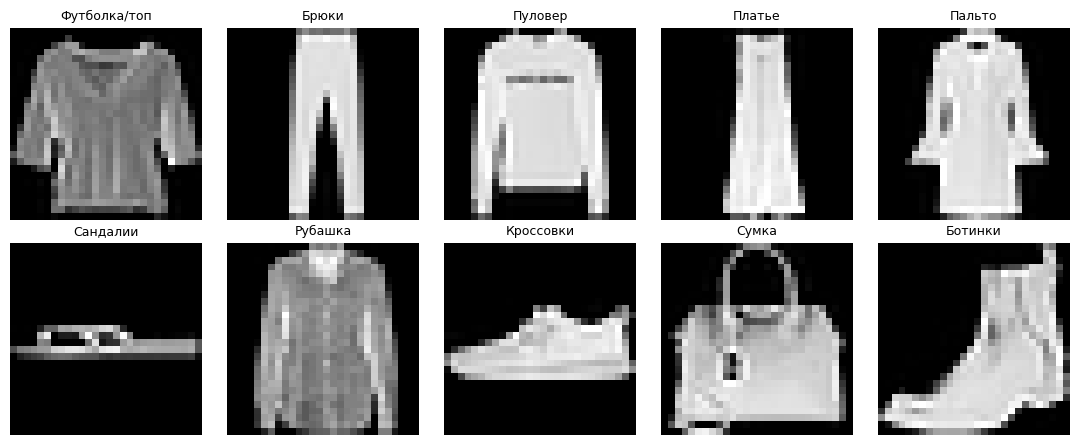

In [5]:
def image_tensors(raw, indices):
    x = raw.data[indices].float().unsqueeze(1) / 127.5 - 1.0
    y = raw.targets[indices].long()
    return TensorDataset(x, y)

train_set = image_tensors(raw_train, train_indices)
val_set = image_tensors(raw_train, val_indices)
test_set = image_tensors(raw_test, torch.arange(len(raw_test)))

def make_loader(dataset, shuffle=False, batch_size=None):
    if batch_size is None:
        batch_size = BATCH_SIZE
    # Сброс генератора задаёт каждой модели один и тот же порядок батчей.
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

# Посмотрим на примеры данных.
print('обучение / валидация / тест:', len(train_set), len(val_set), len(test_set))
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for label, ax in enumerate(axes.ravel()):
    idx = torch.where(train_set.tensors[1] == label)[0][0]
    ax.imshow((train_set.tensors[0][idx, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Классификатор ViT по шагам

Входной тензор будет проходить через модель следующим образом:

```
изображение                                    (B, 1, 28, 28)
  → Conv2d(kernel=stride=P)                     (B, D, 28/P, 28/P)
  → разворачиваем пространственную сетку        (B, N, D), N = (28/P)²
  → добавляем обучаемый CLS в начало            (B, N+1, D)
  → прибавляем позиционные эмбеддинги           (B, N+1, D)
  → пропускаем через блоки трансформера         (B, N+1, D)
  → финальный LayerNorm, выбираем CLS           (B, D)
  → линейный классификатор                     (B, 10)
```

`B` — размер батча, `D` — размерность эмбеддинга, `N` — количество патчей изображения, а `T=N+1` — длина последовательности с учётом CLS.

### 3.1 Свёрточные эмбеддинги патчей — TODO 1 (1 балл)

В этом задании вам нужно реализовать слой эмбеддингов на основе `Conv2d`. Каждый фильтр должен покрывать ровно один непересекающийся патч. Обучаемые веса фильтра преобразуют этот патч в одну координату эмбеддинга размерности `D`. Также оставьте в `Conv2d` обучаемый (`bias`).

На выходе свёртки получается тензор `(B, D, grid_h, grid_w)`. Flatten мы также включим в наш слой эмбеддингов. Порядок токенов после flatten должны идти **по строкам**: слева направо по первой строке, затем по второй и так далее. После flatten также нужно будет сделать reshape, чтобы итоговый тензор был размерности `(B, N, D)`.



In [6]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size, patch_size, in_channels, embed_dim):
        super().__init__()
        # Требуем делимость размера изображения на P
        assert image_size % patch_size == 0
        self.image_size = image_size
        self.patch_size = patch_size
        self.num_patches = (image_size // patch_size)**2 # Общее число патчей по размерам изображения и патча.
        # TODO 1a: задайте self.proj как описанную выше свёртку Conv2d.
        self.proj = torch.nn.Conv2d(
            in_channels=in_channels,
            kernel_size=patch_size,
            stride=patch_size,
            out_channels=embed_dim,
            bias=True
        )

    def forward(self, images):
        assert images.ndim == 4
        assert images.shape[-2:] == (self.image_size, self.image_size)
        # TODO 1b: примените свёртку, сделайте flatten, переставьте оси.
        x = self.proj(images)
        x = x.flatten(-2, -1).transpose(1, 2)
        return x

Следующая ячейка содержит проверки вашей реализации.

In [7]:
# Заданные фильтры проверяют порядок патчей и пикселей, а также шаг без перекрытия.
patch_test = PatchEmbedding(8, 4, 1, 3)
assert isinstance(patch_test.proj, nn.Conv2d), 'Используйте Conv2d для выделения патчей и их проекции.'
with torch.no_grad():
    patch_test.proj.weight.zero_()
    patch_test.proj.bias.zero_()
    patch_test.proj.weight[0, 0] = 1.0       # Сумма всех 16 пикселей.
    patch_test.proj.weight[1, 0, 0, 0] = 1.0  # Верхний левый пиксель.
    patch_test.proj.weight[2, 0, -1, -1] = 1.0 # Нижний правый пиксель.
    actual = patch_test(torch.arange(64.).reshape(1, 1, 8, 8))
expected = torch.tensor([[[216., 0., 27.], [280., 4., 31.],
                          [728., 32., 59.], [792., 36., 63.]]])
torch.testing.assert_close(actual, expected)
assert PatchEmbedding(28, 7, 1, 16)(torch.randn(2, 1, 28, 28)).shape == (2, 16, 16)
print('✓ Порядок и форма выходных токенов корректны.')

✓ Порядок и форма выходных токенов корректны.


### 3.2 Двунаправленный multi-head self-attention — TODO 2 (2 балла)

Теперь реализуем слой внимания.

Для входа `x` формы `(B, T, D)` self-attention будет работать так:

1. Один слой `Linear(D, 3*D)` вычисляет Q, K, V. После этого разделите его выход на 3 части по последнему измерению (на Q, K и V в отдельности)
2. Приведите каждый из Q, K, V к форме `(B, heads, T, head_dim)`, где `head_dim = D // heads`.
3. Вычислите $A=\operatorname{softmax}(QK^\top/\sqrt{\text{head\_dim}})$  вдоль **размерности ключей** — последней оси.
4. Вычислите `Dropout(A) @ V`, сконкатенируйте выходы голов и примените выходную проекцию и dropout.

Ещё раз напомним: **маску использовать не нужно**. В классификации изображений нет запрета на доступ к будущим токенам.

Метод `forward()` должен возвращать tuple `(output, attn_w)`, где `attn_w` — веса внимания **до dropout**, имеющие размер `(B, heads, T, T)`. Они понадобятся нам для дальнейшего анализа.

In [8]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        # TODO 2a: задайте self.qkv (D -> 3D) и self.out_proj (D -> D).
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.attn_dropout = nn.Dropout(dropout)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.proj_dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, D = x.shape
        # TODO 2b: вычислите QKV, разделите Q/K/V и головы, примените scaling и softmax.
        # nn.functional.softmax
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.reshape(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.reshape(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.reshape(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        qk = torch.matmul(q, k.transpose(-2, -1))
        attn_w = nn.functional.softmax(qk / math.sqrt(self.head_dim), dim=-1)

        # TODO 2c: вычислите результат attention, сконтакетнируйте выходы голов, примените проекцию
        x = self.attn_dropout(attn_w) @ v
        x = x.permute(0, 2, 1, 3).reshape(B, T, self.num_heads * self.head_dim)
        output = self.proj_dropout(self.out_proj(x))
        return (output, attn_w)

Следующая ячейка содержит проверки вашей реализации.

In [9]:
seed_everything(0)
attn_test = MultiHeadSelfAttention(16, 4, dropout=0.0).eval()
x = torch.randn(2, 5, 16)
with torch.no_grad():
    y, a = attn_test(x)
    changed = x.clone()
    changed[:, -1] += torch.randn(16)
    y_changed, _ = attn_test(changed)
assert y.shape == x.shape and a.shape == (2, 4, 5, 5)
torch.testing.assert_close(a.sum(dim=-1), torch.ones(2, 4, 5))
assert (a >= 0).all() and (a[..., 0, -1] > 0).all(), 'Первый токен должен иметь доступ к последнему.'
assert (y[:, 0] - y_changed[:, 0]).abs().max() > 1e-6, 'Проверьте, что внимание смешивает информацию со всех позиций.'
permutation = torch.tensor([3, 0, 4, 1, 2])
with torch.no_grad():
    y_permuted, _ = attn_test(x[:, permutation])
torch.testing.assert_close(y_permuted, y[:, permutation], atol=1e-6, rtol=1e-5)
print('✓ Проверены формы внимания, нормировка строк, смешивание выходов голов внимания и эквивариантность к перестановке.')

✓ Проверены формы внимания, нормировка строк, смешивание выходов голов внимания и эквивариантность к перестановке.


### 3.3 MLP для отдельных токенов и блок трансформера — TODO 3–4 (1 балл)

Теперь определим MLP и объединим его со слоем внимания в блок ViT.

MLP применяется независимо к каждому токену. Используем архитектуру `Linear(D, 4D) → GELU → Linear(4D, D) → Dropout`.

Возьмём блок с **предварительной нормализацией (pre-norm)**:

```
x = x + attention(LayerNorm(x))
x = x + mlp(LayerNorm(x))
```

Нормализация применяется только по последнему измерению: `LayerNorm(embed_dim)`. Блок возвращает `(x, attn_w)`, где `attn_w` — веса его слоя внимания.

In [10]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        # TODO 3: создайте self.net из четырёх описанных выше слоёв.
        # (без LayerNorm: нормализация выполняется внутри ViTBlock)
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

In [11]:
class ViTBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        # TODO 4a: задайте self.norm1, self.attn, self.norm2, self.mlp.
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = FeedForward(embed_dim, dropout)

    def forward(self, x):
        # TODO 4b: norm -> self-attn -> residual -> norm -> mlp -> residual
        # выход — (output, attn_w).

        output, attn_w = self.attn(self.norm1(x))
        x = x + output
        x = x + self.mlp(self.norm2(x))
        return x, attn_w

Следующая ячейка содержит проверки вашей реализации.

In [12]:
seed_everything(0)
x = torch.randn(2, 7, 16)
ffn_test = FeedForward(16, dropout=0.0).eval()
with torch.no_grad():
    whole = ffn_test(x)
    separate = torch.cat([ffn_test(x[:, i:i+1]) for i in range(7)], dim=1)
torch.testing.assert_close(whole, separate)
block_test = ViTBlock(16, 4, dropout=0.0).eval()
y, a = block_test(x)
assert y.shape == x.shape and a.shape == (2, 4, 7, 7)
# Если оба внутренних слоя выдают нули, блок обязан возвращать вход без изменений.
with torch.no_grad():
    for p in list(block_test.attn.parameters()) + list(block_test.mlp.parameters()):
        p.zero_()
    identity_output, _ = block_test(x)
torch.testing.assert_close(identity_output, x)
print('✓ Проверены MLP, размерности блоков и resudual connections.')

✓ Проверены MLP, размерности блоков и resudual connections.


### 3.4 Полный классификатор ViT — TODO 5 (1 балл)

Наконец, создадим класс нашей модели ViT.

Вам нужно определить его компоненты:

- `PatchEmbedding`;
- обучаемый параметр CLS размера `(1,1,D)`;
- обучаемые позиционные эмбеддинги размера `(1,N+1,D)`;
- список блоков ViT в `ModuleList`;
- финальный LayerNorm;
- классификационную голову `Linear(D, num_classes)`.

Расширьте CLS по измерению батча, не создавая отдельный обучаемый параметр для каждого примера (используйте `expand`). Добавьте его в начало последовательности эмбеддингов патчей (на позицию). После последнего блока и финального LayerNorm примените классификатор **только к эмбеддингу CLS**. Возвращайте логиты **без softmax**: в качестве лосс-функции мы будем использовать `cross_entropy`.

Метод класса `forward_tokens` выполняет обычный прямой проход ViT. Параметр `use_positions` определяет, добавляются ли позиционные эмбеддинги. При `return_attention=True` возвращайте `(logits, list_of_attention_matrices)`, иначе — только логиты.

In [13]:
class TinyViT(nn.Module):
    def __init__(self, image_size=28, patch_size=4, in_channels=1, num_classes=10,
                 embed_dim=128, num_heads=4, depth=3, dropout=0.1):
        super().__init__()
        self.patch_size = patch_size
        self.image_size = image_size
        self.num_patches = (image_size // patch_size) ** 2
        # TODO 5a: задайте patch_embed, cls_token, pos_embed, blocks, norm, head.
        self.patch_embed = PatchEmbedding(image_size, patch_size, in_channels, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))
        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads, dropout) for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.apply(self._init_weights)
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, images, **kwargs):
        return self.forward_tokens(self.patch_embed(images), **kwargs)

    def forward_tokens(self, patches, use_positions=True, return_attention=False):
        B, N, D = patches.shape
        assert N == self.num_patches

        # TODO 5b: добавьте расширенный CLS в начало. Если use_positions = True, то затем добавьте self.pos_embed
        x = torch.cat((self.cls_token.expand(size=(B, -1, -1)), patches), dim=1)
        if use_positions:
            x = x + self.pos_embed

        # Пропускаем входные токены через блоки ViT.
        attentions = []
        for block in self.blocks:
            x, attention = block(x)
            if return_attention:
                attentions.append(attention)

        # TODO 5c: примените финальную нормализацию и классификатор к CLS
        x = self.norm(x)
        logits = self.head(x[:, 0])

        return (logits, attentions) if return_attention else logits

Следующая ячейка содержит проверки вашей реализации.

In [14]:
seed_everything(0)
test_model = TinyViT(embed_dim=32, num_heads=4, depth=2, dropout=0.0)
images, labels = train_set.tensors[0][:4], train_set.tensors[1][:4]
logits, attentions = test_model(images, return_attention=True)
assert logits.shape == (4, NUM_CLASSES)
assert len(attentions) == 2 and attentions[0].shape == (4, 4, 50, 50)
loss = F.cross_entropy(logits, labels)
assert torch.isfinite(loss)
assert abs(loss.item() - math.log(NUM_CLASSES)) < 0.5
loss.backward()
for name, p in test_model.named_parameters():
    assert p.grad is not None and torch.isfinite(p.grad).all(), f"Градиент отсутствует или содержит NaN/Inf: {name}"
for p in (test_model.patch_embed.proj.weight, test_model.cls_token, test_model.pos_embed):
    assert p.grad.abs().sum() > 0, 'Один из обучаемых входных компонентов не получает градиент.'
print(f"✓ Формы и градиенты ViT корректны; начальные потери {loss.item():.3f} (равномерное предсказание ≈ {math.log(10):.3f}).")

✓ Формы и градиенты ViT корректны; начальные потери 2.272 (равномерное предсказание ≈ 2.303).


## 4. Обучаем классификатор с нуля

Пришло время обучить наш ViT!

Все параметры модели обучаются совместно: свёрточный слой embedding, CLS, позиционный эмбеддинги, attention, MLP и классификатор. Предобученных весов и заранее вычисленных эмбеддингов здесь нет.

Цикл обучения уже написан. В нём используются AdamW, gradient clipping и cosine scheduler. В процессе обучения сохраняются лучшие на данный момент веса модели с наименьшей **функцией потерь на валидации**. Обучающие кривые показывают метрики, накопленные по мини-батчам в течение эпохи с включённым dropout, валидационные метрики вычисляются после эпохи в режиме `eval()`.

Сначала зададим гиперпараметры модели. После выполнения задания вы сможете менять их и обучать другие варианты ViT:

In [15]:
# Гиперпараметры модели
IMAGE_SIZE = 28
IN_CHANNELS = 1
PATCH_SIZE = 4
EMBED_DIM = 128
NUM_HEADS = 4
DEPTH = 3
DROPOUT = 0.1
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
assert IMAGE_SIZE % PATCH_SIZE == 0
assert EMBED_DIM % NUM_HEADS == 0

def model_config(patch_size):
    return dict(image_size=IMAGE_SIZE, patch_size=patch_size, in_channels=IN_CHANNELS,
                num_classes=NUM_CLASSES, embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
                depth=DEPTH, dropout=DROPOUT)

Далее определим функции обучения и оценки качества.

In [16]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=-1) == y).sum().item()
        total += len(y)
    return {"loss": total_loss / total, "accuracy": correct / total}

def fit_model(model):
    seed_everything(SEED)

    # Создаём даталоадеры
    train_loader = make_loader(train_set, shuffle=True)
    val_loader = make_loader(val_set)

    # Настраиваем оптимизатор
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    # Оцениваем модель до обучения
    baseline = evaluate(model, val_loader)
    print(f"P={model.patch_size} | параметров={sum(p.numel() for p in model.parameters()):,} | "
          f"валидация до обучения: потери={baseline['loss']:.3f}, доля верных ответов={baseline['accuracy']:.1%}")

    # Инициализируем логгеры метрик.
    history = []
    best_loss, best_state, best_epoch = float("inf"), None, None
    train_seconds = 0.0
    synchronize()
    wall_start = time.perf_counter()

    # Обучение.
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        synchronize()
        start = time.perf_counter()

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)

            loss = F.cross_entropy(logits, y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)

            # логгируем метрики.
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(-1) == y).sum().item()
            total += len(y)

        # Вывод метрик и оценка модели после эпохи обучения.
        synchronize()
        epoch_seconds = time.perf_counter() - start
        train_seconds += epoch_seconds
        validation = evaluate(model, val_loader)
        history.append(dict(epoch=epoch, train_loss=total_loss / total, train_acc=correct / total,
                            val_loss=validation["loss"], val_acc=validation["accuracy"]))

        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        scheduler.step()
        print(f"эпоха {epoch:2d}/{EPOCHS} | потери на обучении {total_loss/total:.3f}, доля верных {correct/total:.1%} | "
              f"потери на валидации {validation['loss']:.3f}, доля верных {validation['accuracy']:.1%} | обучение {epoch_seconds:.1f}с")

    # Итоговая запись метрик и оценка.
    synchronize()
    wall_seconds = time.perf_counter() - wall_start
    model.load_state_dict(best_state)
    model.eval()
    Path(CKPT_DIR).mkdir(exist_ok=True)
    torch.save({"state_dict": best_state, "config": model_config(model.patch_size),
                "seed": SEED, "best_epoch": best_epoch, "model_class": type(model).__name__},
                f"{CKPT_DIR}/{type(model).__name__}_p{model.patch_size}.pt")
    best = history[best_epoch - 1]
    print(f"Лучшая эпоха: {best_epoch}; обучение {train_seconds:.1f}с; полное время {wall_seconds:.1f}с")
    return dict(model=model, history=history, baseline=baseline, best_epoch=best_epoch,
                val_loss=best["val_loss"], val_acc=best["val_acc"], train_seconds=train_seconds,
                wall_seconds=wall_seconds, parameters=sum(p.numel() for p in model.parameters()),
                updates=EPOCHS * len(train_loader))

def plot_history(result, title):
    '''
    Вспомогательная функция построения графиков обучения.
    '''
    h = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, train_key, val_key, ylabel in [
        (axes[0], "train_loss", "val_loss", 'Кросс-энтропия'),
        (axes[1], "train_acc", "val_acc", 'Доля верных ответов')
    ]:
        ax.plot([r["epoch"] for r in h], [r[train_key] for r in h], label='обучение (в течение эпохи)')
        ax.plot([r["epoch"] for r in h], [r[val_key] for r in h], label='валидация')
        ax.axvline(result["best_epoch"], ls="--", color="gray", alpha=0.6, label='выбранная эпоха')
        ax.set(xlabel='Эпоха', ylabel=ylabel, title=f"{title}: {ylabel}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

Запустим обучение и построим графики. При корректной реализации функция потерь после обучения должна быть ~0.53, accuracy ~82.0%.

P=4 | параметров=605,066 | валидация до обучения: потери=2.337, доля верных ответов=10.5%
эпоха  1/8 | потери на обучении 1.675, доля верных 40.4% | потери на валидации 1.262, доля верных 56.8% | обучение 1.7с
эпоха  2/8 | потери на обучении 1.112, доля верных 61.7% | потери на валидации 0.879, доля верных 71.1% | обучение 1.1с
эпоха  3/8 | потери на обучении 0.833, доля верных 71.3% | потери на валидации 0.712, доля верных 74.0% | обучение 1.1с
эпоха  4/8 | потери на обучении 0.709, доля верных 75.4% | потери на валидации 0.664, доля верных 76.8% | обучение 1.1с
эпоха  5/8 | потери на обучении 0.635, доля верных 78.2% | потери на валидации 0.587, доля верных 79.3% | обучение 1.3с
эпоха  6/8 | потери на обучении 0.579, доля верных 79.9% | потери на валидации 0.587, доля верных 79.6% | обучение 1.2с
эпоха  7/8 | потери на обучении 0.535, доля верных 81.3% | потери на валидации 0.525, доля верных 81.7% | обучение 1.1с
эпоха  8/8 | потери на обучении 0.510, доля верных 82.7% | потери на в

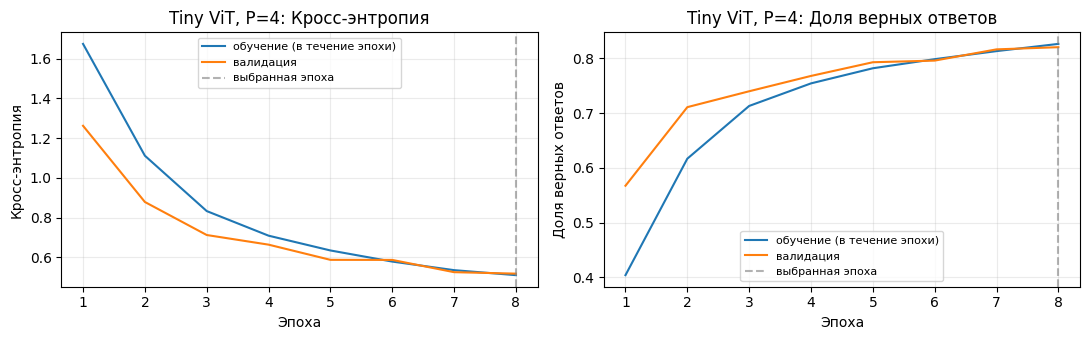

In [17]:
# Создаём модель.
model = TinyViT(**model_config(PATCH_SIZE)).to(device)
main_result = fit_model(model)
model = main_result["model"]
plot_history(main_result, f"Tiny ViT, P={PATCH_SIZE}")

Посмотрим предсказания модели и правильные метки для нескольких изображений

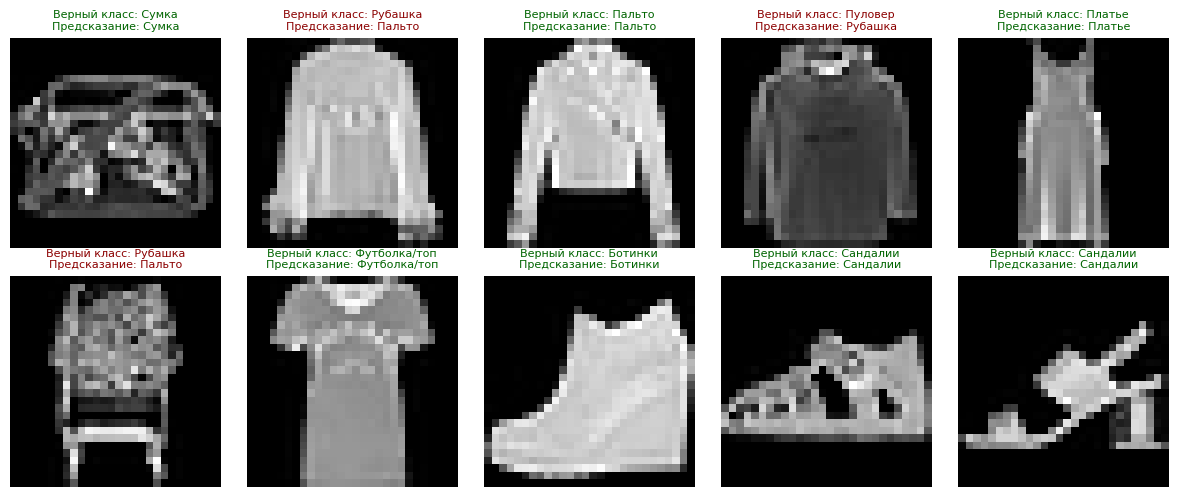

In [18]:
# Фиксируем валидационную подвыборку для двух следующих исследований.
exp_x = val_set.tensors[0][:EXPERIMENT_IMAGES].to(device)
exp_y = val_set.tensors[1][:EXPERIMENT_IMAGES].to(device)
model.eval()
with torch.no_grad():
    exp_logits = model(exp_x)
    exp_predictions = exp_logits.argmax(dim=-1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    true_id, pred_id = int(exp_y[i]), int(exp_predictions[i])
    ax.imshow((exp_x[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Верный класс: {class_names[true_id]}\nПредсказание: {class_names[pred_id]}", fontsize=8,
                 color="darkgreen" if true_id == pred_id else "darkred")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Итоговая оценка на отложенной тестовой выборке

Завершите эксперименты выше и зафиксируйте все решения, и после этого и один раз оцените соответствующее сохранённое состояние модели на официальной тестовой выборке.

Матрица ошибок помогает увидеть, какие категории одежды модель путает. Она не участвует в выборе модели.

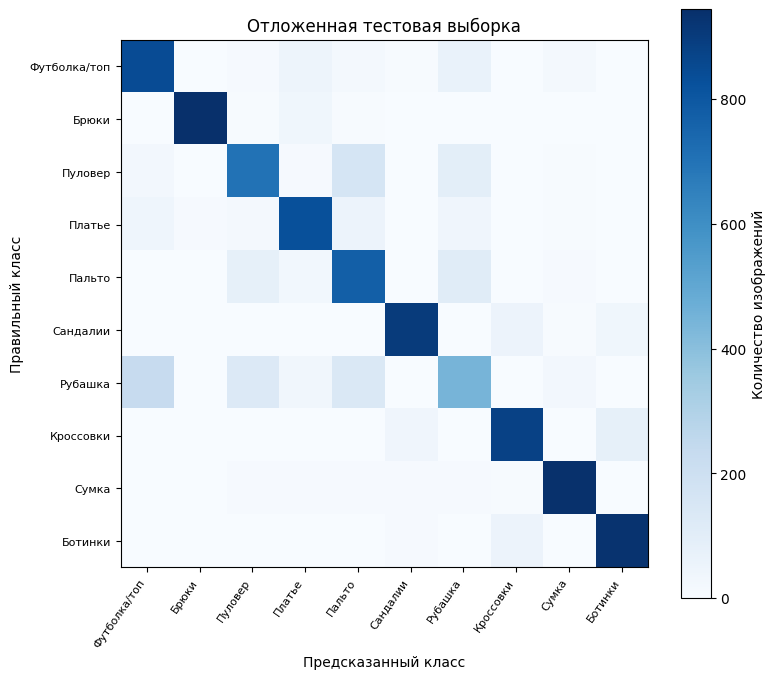

In [19]:
confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
model.eval()
with torch.no_grad():
    for x, y in make_loader(test_set):
        prediction = model(x.to(device)).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * NUM_CLASSES + prediction,
                                    minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES), labels=class_names, fontsize=8)
ax.set(xlabel='Предсказанный класс', ylabel='Правильный класс', title=f"Отложенная тестовая выборка")
plt.colorbar(im, ax=ax, label='Количество изображений')
plt.tight_layout(); plt.show()

In [20]:
model

TinyViT(
  (patch_embed): PatchEmbedding(
    (proj): Conv2d(1, 128, kernel_size=(4, 4), stride=(4, 4))
  )
  (blocks): ModuleList(
    (0-2): 3 x ViTBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
        (proj_dropout): Dropout(p=0.1, inplace=False)
      )
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (mlp): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
  )
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (head): Linear(in_features=128, out_featur

Поздравляем! Вы реализовали и обучили собственный ViT!

Теперь немного поэкспериментируем с моделью $\downarrow$

## 5. Эксперимент 1 — знает ли ViT, где должен находиться патч? (5 баллов в сумме)

В этом эксперименте мы будем менять порядок патчей в ViT и смотреть, как это влияет на результат.

**Перед выполнением задания:** подумайте и сделайте предположение, в каких из вариантов ниже изменятся итоговые логиты и/или предсказания классов модели на входящие картинки. Изменение логитов не обязательно означает изменение предсказанного класса!

- **A. Делаем перестановку патчей до positional encodings:** при инференсе переставляем эмбеддинги патчей *до* добавления позиционных эмбеддингов.
- **B. Делаем перестановку патчей после positional encodings:** при инференсе сначала добавляем позиционные эмбеддинги, затем переставляем токены патчей вместе с их позиционными эмбеддингами. CLS остаётся на позиции 0.
- **C. Убираем positional encodings только при инференсе:** отключаем позиционные эмбеддинги у модели, обученной с ними, и сравниваем с исходной моделью. Патчи не переставляем.
- **D. Обучаем без positional encodings:** обучаем отдельный ViT с нуля с отключёнными позиционными эмбеддингами и сравниваем его с исходной моделью, обученной с позициями.

В A–C мы можем использовать веса уже обученной модели выше, а для D понадобится обучить новую модель. Во всех четырёх случаях мы будем сравнивать результат с исходной моделью: без перестановки патчей и с positional encodings. A/B проверяют влияние на результат порядка патчей, C/D — разницу между удалением позиций при инференсе и обучением без них. Мы будем сравнивать качество на валидационном сете и изменения логитов на входящие картинки: **инвариантность к перестановке и качество классификации — разные вещи**.

**Ваши предположения до запуска:** в каких из вариантов ниже изменятся итоговые логиты и/или предсказания классов модели на входящие картинки?

A: логиты меняются

B: логиты не меняются

C: логиты меняются

D: логиты меняются

### 5.1 Меняем forward pass сети — TODO E1 (1 балл)

Чтобы добавить логику перемешивания патчей, нам нужно переопределить forward pass сети. Оставим исходный `TinyViT` без изменений и создадим подкласс `TinyViTShuffle` с новым методом `forward()`. Он наследует те же параметры и слои, что были в `TinyViT`: мы только добавим новую логику в `forward()`.

Добавим в `forward()` два новых аргумента:

- `permutation_stage`: где выполнять перестановку патчей — до или после добавления позиционных эмбеддингов. При `None` перестановки нет, даже если задан seed
- `seed`: начальное состояние генератора для создания перестановки. Его нужно задать, если `permutation_stage != None`. Одинаковые seed и количество патчей задают одинаковый порядок для всех изображений в батче, и повторные вызовы `forward()` создают ту же перестановку. Используйте предложенный локальный генератор, чтобы не менять состояние глобального генератора случайных чисел.

Ваша задача — применить перестановку в двух местах:

1. **E1a:** до добавления позиций — переставьте `patches` вдоль измерения токенов.
2. **E1b:** после добавления позиций — оставьте `x[:, :1]` (CLS) без изменений и переставьте только `x[:, 1:]`. То есть, содержимое патча и его позиционный вектор должны перемещаться вместе.

Считаем, что `permutation[j]` — индекс исходного патча, который окажется на позиции `j`.

In [21]:
def patch_order_from_seed(num_patches, seed, device):
    """Индексы патчей от локального генератора с заданным seed. None — без перестановки."""
    if seed is None:
        return None
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randperm(num_patches, generator=generator).to(device)

In [22]:
class TinyViTShuffle(TinyViT):
    def forward(self, images, seed=None, permutation_stage=None,
                use_positions=True, return_attention=False):
        patches = self.patch_embed(images)
        B, N, D = patches.shape
        assert N == self.num_patches
        if permutation_stage is not None:
            assert permutation_stage in ("before_pos", "after_pos")
            assert seed is not None

        if permutation_stage == "before_pos":
            # TODO E1a: перемешайте эмбеддинги патчей до добавления позиционных эмбеддингов.
            permutation = patch_order_from_seed(N, seed, patches.device)
            patches = torch.index_select(patches, dim=1, index=permutation)

        # Добавьте расширенный CLS в начало. Если use_positions = True, то затем добавьте self.pos_embed
        # Вы уже реализовали это в TinyViT — можно использовать тот же код.
        x = torch.cat((self.cls_token.expand(size=(B, -1, -1)), patches), dim=1)
        if use_positions:
            x = x + self.pos_embed

        if permutation_stage == "after_pos":
            # TODO E1b: оставьте CLS на месте, перемешайте токены патчей.
            permutation = patch_order_from_seed(N, seed, patches.device)
            permutation = torch.cat((torch.tensor([0], device=permutation.device), permutation + 1))
            x = torch.index_select(x, dim=1, index=permutation)

        attentions = []
        for block in self.blocks:
            x, attention = block(x)
            if return_attention:
                attentions.append(attention)
        logits = self.head(self.norm(x)[:, 0])
        return (logits, attentions) if return_attention else logits

Следующая ячейка проверяет вашу реализацию. При `permutation_stage=None` и включённых позициях подкласс должен воспроизводить исходные логиты и веса внимания. Seed задаёт порядок только тогда, когда выбран этап перестановки.

In [23]:
base_model = main_result["model"]
base_model.eval()
shuffle_model = TinyViTShuffle(**model_config(base_model.patch_size)).to(device)
shuffle_model.load_state_dict(base_model.state_dict(), strict=True)
shuffle_model.eval()

check_images = exp_x[:8]
with torch.no_grad():
    base_logits, base_attention = base_model(check_images, return_attention=True)
    copied_logits, copied_attention = shuffle_model(check_images, permutation_stage=None, return_attention=True)
    torch.testing.assert_close(copied_logits, base_logits, atol=2e-5, rtol=1e-4)
    for original_attention, new_attention in zip(base_attention, copied_attention):
        torch.testing.assert_close(new_attention, original_attention, atol=2e-5, rtol=1e-4)

    # Сам по себе seed не должен включать перестановку.
    torch.testing.assert_close(shuffle_model(check_images, seed=0), base_logits, atol=2e-5, rtol=1e-4)

    rng_before = torch.random.get_rng_state().clone()
    seeded_first = shuffle_model(check_images, seed=0, permutation_stage="before_pos")
    seeded_second = shuffle_model(check_images, seed=0, permutation_stage="before_pos")
    torch.testing.assert_close(seeded_first, seeded_second)
    assert torch.equal(rng_before, torch.random.get_rng_state()), 'Не сбрасывайте и не расходуйте глобальный генератор для создания перестановки.'

order0 = patch_order_from_seed(shuffle_model.num_patches, 0, device)
order1 = patch_order_from_seed(shuffle_model.num_patches, 1, device)
assert not torch.equal(order0, order1), 'Эти два seed должны давать разные перестановки патчей.'
assert torch.equal(order0.sort().values, torch.arange(shuffle_model.num_patches, device=device))
assert base_model.cls_token.data_ptr() != shuffle_model.cls_token.data_ptr(), 'Используйте отдельные экземпляры моделей.'
print('✓ Веса скопированы; permutation_stage=None совпадает с TinyViT; seed=0 воспроизводим; глобальный генератор не изменён.')

✓ Веса скопированы; permutation_stage=None совпадает с TinyViT; seed=0 воспроизводим; глобальный генератор не изменён.


### 5.2 Запускаем A–C с уже обученными параметрами (1 балл)

Если создать экземпляр TinyViTShuffle с нуля:

`model = TinyViTShuffle()`

то получим модель с заново инициализированными весами, которую пришлось бы снова обучать. Однако для A–C нужно лишь изменить поведение уже обученного TinyViT при инференсе. Поэтому создадим TinyViTShuffle и загрузим в него веса обученного выше TinyViT.

In [24]:
SHUFFLE_SEED = SEED + 1
shuffle_model.eval()

# Изображения для этих экспериментов.
exp_x = val_set.tensors[0][:EXPERIMENT_IMAGES].to(device)
exp_y = val_set.tensors[1][:EXPERIMENT_IMAGES].to(device)

with torch.no_grad():
    # Запускаем модель в исходном режиме, без перестановки патчей.
    original = shuffle_model(exp_x)
    # Переставьте патчи ДО добавления positional encodings, используя SHUFFLE_SEED.
    # Позиционные эмбеддинги включены.
    before_positions = shuffle_model(exp_x, permutation_stage='before_pos', seed=SHUFFLE_SEED)
    # Переставьте патчи ПОСЛЕ добавления positional encodings, используя SHUFFLE_SEED.
    # Позиционные эмбеддинги включены.
    after_positions = shuffle_model(exp_x, permutation_stage='after_pos', seed=SHUFFLE_SEED)
    # Запустите модель без позиционных эмбеддингов и без перестановки патчей.
    no_positions = shuffle_model(exp_x, use_positions=False)

Ниже приведена функция перестановки патчей самого изображения, а не их эмбеддингов. Она позволяет показать, что «видит» трансформер после перестановки эмбеддингов. При одинаковом seed перестановка патчей исходного изображения должна быть эквивалентна перестановке их эмбеддингов до добавления позиций.

In [25]:
def shuffle_image_patches(images, seed, patch_size):
    '''
    Вспомогательная функция перестановки патчей изображения для визуализации.
    '''
    grid = images.shape[-1] // patch_size
    permutation = patch_order_from_seed(grid * grid, seed, images.device)
    if permutation is None:
        return images.clone()
    result = torch.empty_like(images)
    for destination, source in enumerate(permutation.cpu().tolist()):
        dr, dc = divmod(destination, grid)
        sr, sc = divmod(source, grid)
        result[:, :, dr*patch_size:(dr+1)*patch_size, dc*patch_size:(dc+1)*patch_size] = \
            images[:, :, sr*patch_size:(sr+1)*patch_size, sc*patch_size:(sc+1)*patch_size]
    return result

# Проверка: перестановка целых патчей изображения эквивалентна перестановке выходов свёртки.
with torch.no_grad():
    shuffled_images = shuffle_image_patches(exp_x, SHUFFLE_SEED, shuffle_model.patch_size)
    shuffled_image_logits = shuffle_model(shuffled_images)
torch.testing.assert_close(shuffled_image_logits, before_positions, atol=2e-5, rtol=1e-4)

Теперь сравним случаи A–C: посмотрим, как меняются логиты и предсказанные классы.

A: содержимое переставлено, positional encodings фиксированы
  max |разница логитов|=7.52e+00; изменено предсказаний=73/100
B: содержимое и positional encodings переставлены вместе
  max |разница логитов|=9.54e-07; изменено предсказаний=0/100
C: positional encodings отключены только при инференсе
  max |разница логитов|=6.15e+00; изменено предсказаний=66/100


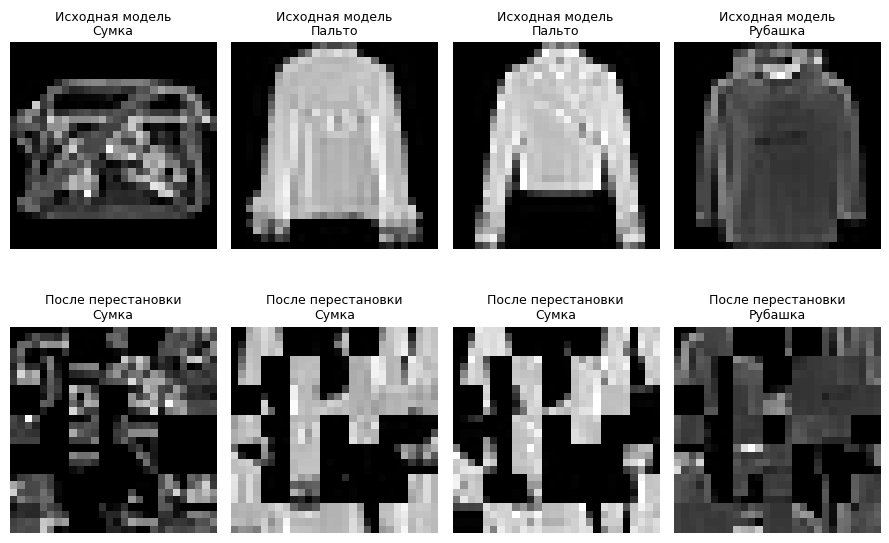

In [26]:
shuffle_results = {}
def report_shuffle(name, reference, changed):
    difference = (reference - changed).abs().max().item()
    changed_labels = (reference.argmax(-1) != changed.argmax(-1)).sum().item()
    shuffle_results[name] = dict(max_logit_difference=difference, changed_labels=changed_labels)
    print(f"{name}\n  max |разница логитов|={difference:.2e}; "
          f"изменено предсказаний={changed_labels}/{len(reference)}")

report_shuffle('A: содержимое переставлено, positional encodings фиксированы', original, before_positions)
report_shuffle('B: содержимое и positional encodings переставлены вместе', original, after_positions)
report_shuffle('C: positional encodings отключены только при инференсе', original, no_positions)

fig, axes = plt.subplots(2, 4, figsize=(9, 6))
for i in range(4):
    for row, batch, logits, title in [(0, exp_x, original, 'Исходная модель'),
                                       (1, shuffled_images, before_positions, 'После перестановки')]:
        axes[row, i].imshow((batch[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[row, i].set_title(f"{title}\n{class_names[int(logits[i].argmax())]}", fontsize=9)
        axes[row, i].axis("off")
plt.tight_layout(h_pad=2.0); plt.show()

Измерим долю верных ответов на валидации для вариантов A–C:

Исходная модель: обучение и оценка с positional encodings: доля верных ответов на валидации = 82.0%
A: перестановка содержимого до добавления positional encodings: доля верных ответов на валидации = 25.2%
B: содержимое и positional encodings переставлены вместе: доля верных ответов на валидации = 82.0%
C: positional encodings отключены только при инференсе: доля верных ответов на валидации = 32.2%


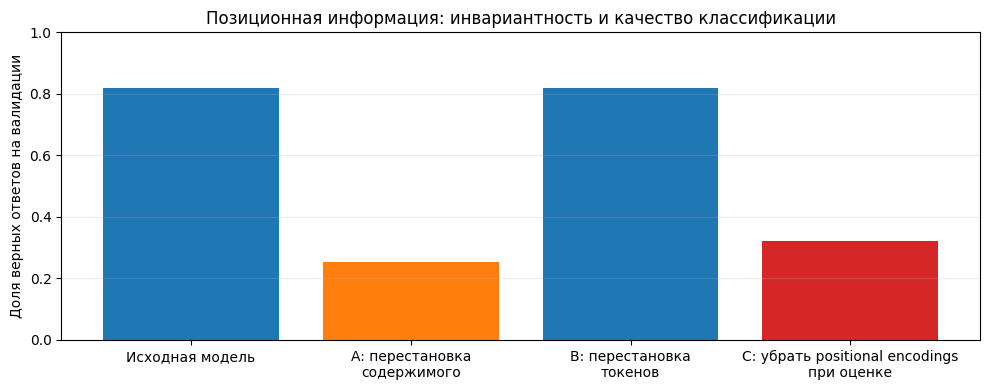

In [27]:
@torch.no_grad()
def evaluate_variant(model, loader, **forward_kwargs):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        predictions = model(x.to(device), **forward_kwargs).argmax(dim=-1)
        correct += (predictions == y.to(device)).sum().item()
        total += len(y)
    return correct / total

# Оцениваем на ВСЕЙ валидации, а не только на 100 примерах из проверок перестановки.
validation_cases = [
    ('Исходная модель: обучение и оценка с positional encodings', shuffle_model, {}),
    ('A: перестановка содержимого до добавления positional encodings', shuffle_model,
     {"seed": SHUFFLE_SEED, "permutation_stage": "before_pos"}),
    ('B: содержимое и positional encodings переставлены вместе', shuffle_model,
     {"seed": SHUFFLE_SEED, "permutation_stage": "after_pos"}),
    ('C: positional encodings отключены только при инференсе', shuffle_model, {"use_positions": False}),
]

# Вычисляем долю верных ответов на валидации.
position_accuracies = {}
for label, variant, kwargs in validation_cases:
    accuracy = evaluate_variant(variant, make_loader(val_set), **kwargs)
    position_accuracies[label] = accuracy
    print(f"{label}: доля верных ответов на валидации = {accuracy:.1%}")

# Визуализация.
fig, ax = plt.subplots(figsize=(10, 4))
short_names = ['Исходная модель', 'A: перестановка\nсодержимого', 'B: перестановка\nтокенов', 'C: убрать positional encodings\nпри оценке']
ax.bar(short_names, list(position_accuracies.values()), color=["tab:blue", "tab:orange", "tab:blue", "tab:red"])
ax.set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Позиционная информация: инвариантность и качество классификации')
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

Какие результаты вы получили? Совпали ли они с вашими предварительными ожиданиями?

### 5.3 Случай D: обучаем новую модель без positional encodings (1 балл)

Для D создадим подкласс `TinyViTNoPositions`, метод `forward()` которого **всегда** использует `use_positions=False`. Поменяв так `forward()`, мы получим, что позиционные эмбеддинги будут отключены при вызовах функций train и eval.

При этом `TinyViTNoPositions` унаследует positional encodings из родительского класса, но этот параметр использоваться не будет. Все остальные параметры будут обучаться с нуля. **Не загружайте в эту модель веса модели, обученной с позициями.** Во время обучения переставлять патчи не нужно: без позиций изменение порядка патчей и так не должно менять выход CLS в режиме `eval()`.

Используем то же разбиение данных, настройки оптимизатора, количество эпох и порядок мини-батчей. Обратите внимание, что начальные веса обученных моделей могут различаться, поэтому разница в качестве может отчасти быть обусловлена разницей инициализации.

In [28]:
class TinyViTNoPositions(TinyViTShuffle):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_embed.requires_grad_(False)  # Не используется и не оптимизируется.

    def forward(self, images, seed=None, permutation_stage=None, return_attention=False):
        # TODO E1c: вызовите forward() родительского класса, передав эти аргументы,
        # но ВСЕГДА задавайте use_positions=False — и при обучении, и при инференсе.
        return super().forward(images, seed=seed, permutation_stage=permutation_stage,
                use_positions=False, return_attention=return_attention)

Следующая ячейка содержит проверки вашей реализации.

In [29]:
# Эта маленькая необученная модель нужна только для проверки нового forward()
no_pos_check = TinyViTNoPositions(embed_dim=32, num_heads=4, depth=1, dropout=0.0).to(device)
no_pos_check.eval()
with torch.no_grad():
    expected_no_pos = TinyViTShuffle.forward(no_pos_check, check_images, use_positions=False)
    actual_no_pos = no_pos_check(check_images)
    torch.testing.assert_close(actual_no_pos, expected_no_pos, atol=2e-5, rtol=1e-4)
    # Сильное изменение неиспользуемых positional encodings не должно влиять на результат.
    no_pos_check.pos_embed.add_(100.0)
    torch.testing.assert_close(no_pos_check(check_images), actual_no_pos, atol=2e-5, rtol=1e-4)
no_pos_check.train()
F.cross_entropy(no_pos_check(check_images), exp_y[:len(check_images)]).backward()
assert no_pos_check.pos_embed.grad is None
assert no_pos_check.patch_embed.proj.weight.grad is not None
print('✓ Positional encodings отключены при обучении и инференсе; проекция патчей получает градиенты.')
del no_pos_check

✓ Positional encodings отключены при обучении и инференсе; проекция патчей получает градиенты.


Теперь инициализируем и обучим новую модель.

P=4 | параметров=605,066 | валидация до обучения: потери=2.287, доля верных ответов=16.5%
эпоха  1/8 | потери на обучении 1.765, доля верных 35.1% | потери на валидации 1.502, доля верных 42.9% | обучение 1.1с
эпоха  2/8 | потери на обучении 1.358, доля верных 50.0% | потери на валидации 1.182, доля верных 57.2% | обучение 1.1с
эпоха  3/8 | потери на обучении 1.126, доля верных 59.4% | потери на валидации 1.042, доля верных 62.3% | обучение 1.1с
эпоха  4/8 | потери на обучении 1.018, доля верных 63.0% | потери на валидации 0.914, доля верных 67.7% | обучение 1.1с
эпоха  5/8 | потери на обучении 0.914, доля верных 67.3% | потери на валидации 0.833, доля верных 70.8% | обучение 1.1с
эпоха  6/8 | потери на обучении 0.851, доля верных 70.0% | потери на валидации 0.855, доля верных 68.3% | обучение 1.1с
эпоха  7/8 | потери на обучении 0.811, доля верных 71.5% | потери на валидации 0.770, доля верных 72.9% | обучение 1.1с
эпоха  8/8 | потери на обучении 0.783, доля верных 72.6% | потери на в

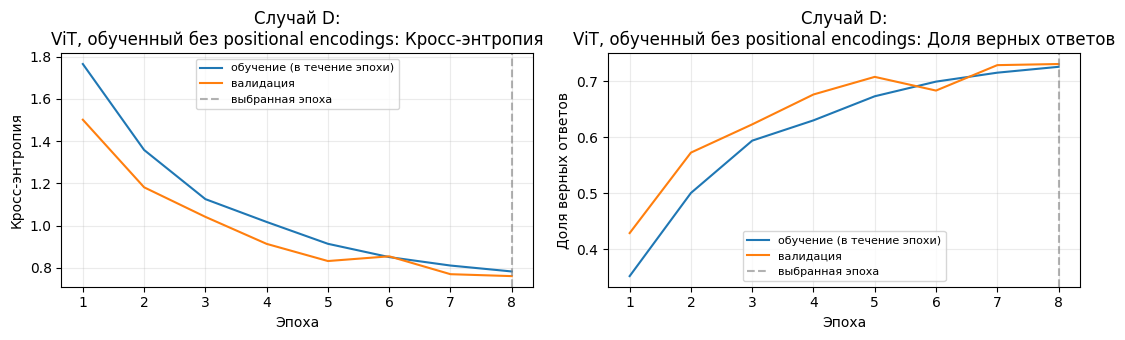

In [30]:
seed_everything(SEED)
no_pos_model = TinyViTNoPositions(**model_config(PATCH_SIZE)).to(device)
no_pos_result = fit_model(no_pos_model)
no_pos_model = no_pos_result["model"]
plot_history(no_pos_result, 'Случай D:\nViT, обученный без positional encodings')
# Имена файлов весов зависят от класса модели: исходный ViT не будет перезаписан.

Получим логиты обученной модели и сравним их с логитами исходной модели.

Заметим снова, что эти логиты получены из двух по-разному обученных моделей: хотя бы случайная иницализация их весов была разной. Поэтому абсолютные значения и масштабы логитов этих двух моделей могут сильно различаться. Поэтому логичнее использовать долю верных ответов на одной и той же валидационной выборке для сравнения качества этих двух моделей.

In [31]:
no_pos_model.eval()
with torch.no_grad():
    trained_no_positions = no_pos_model(exp_x)

report_shuffle('D: модель обучена без positional encodings', original, trained_no_positions)

D: модель обучена без positional encodings
  max |разница логитов|=4.99e+00; изменено предсказаний=21/100


Вычислим долю верных ответов новой модели на валидации и сравним все варианты A–D с исходной моделью.

D: обучение и оценка без positional encodings: доля верных ответов на валидации = 73.1%


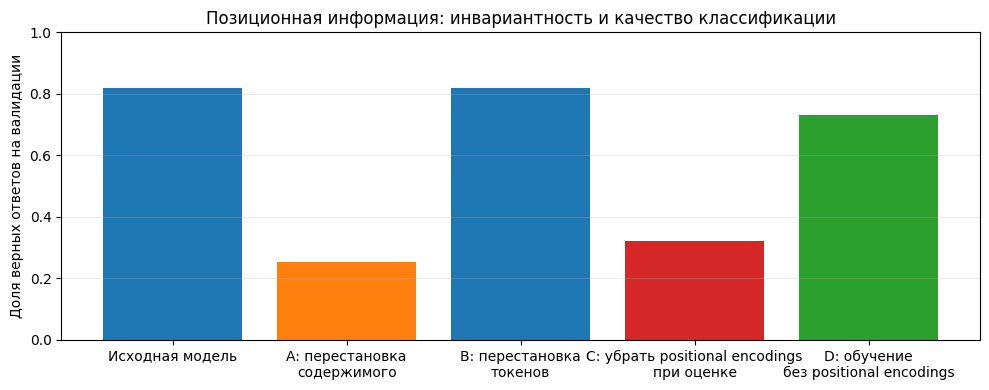

In [32]:
# A–C уже оценены; добавляем D один раз, в том числе при повторном запуске ячейки.
validation_cases = validation_cases[:4] + [
    ('D: обучение и оценка без positional encodings', no_pos_model, {})
]

# Вычисляем долю верных ответов на валидации.
label, variant, kwargs = validation_cases[-1]
accuracy = evaluate_variant(variant, make_loader(val_set), **kwargs)
position_accuracies[label] = accuracy
print(f"{label}: доля верных ответов на валидации = {accuracy:.1%}")

# Визуализация.
fig, ax = plt.subplots(figsize=(10, 4))
short_names = ['Исходная модель', 'A: перестановка\nсодержимого', 'B: перестановка\nтокенов', 'C: убрать positional encodings\nпри оценке', 'D: обучение\nбез positional encodings']
ax.bar(short_names, list(position_accuracies.values()), color=["tab:blue", "tab:orange", "tab:blue", "tab:red", "tab:green"])
ax.set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Позиционная информация: инвариантность и качество классификации')
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### Обсуждение (200–300 слов, 2 балла)

1. Приведите максимальные различия логитов и количество изменившихся предсказаний для A–D. Во всех четырёх случаях используйте исходную модель как точку отсчёта. Чем различаются изменения в C и D? Почему разница логитов в D не измеряет изолированно эффект позиционных эмбеддингов?
2. Объясните разницу между перемещением содержимого до или после добавления positional encodings. Почему выходы для патчей эквивариантны относительно перестановки, а итоговое предсказание по CLS инвариантно? Опишите, что происходит с Q, K, V и строками и столбцами матрицы внимания.
3. Сравните долю верных ответов исходной модели, C и D на валидации. Достаточно ли одного C, чтобы судить о пользе позиционных эмбеддингов? Что добавляет D и какие ограничения остаются?
4. Почему для seed перестановки нужен локальный генератор, а не сброс глобального seed внутри `forward`?

**Ваш ответ:**
1. В ячейке ниже код для получения максимальных различий логитов и количества изменившихся предсказаний для A–D.   
   Рез-ты:
    | exp  | max logits diff  | изменено предсказаний  |
    |---|---|---|
    | original  | 0.00e+00 | 0/100  |
    | A  | 7.52e+00  | 73/100  |
    | B  | 9.54e-07  | 0/100 |
    | C  | 6.15e+00  | 66/100  |
    | D  | 4.99e+00  | 21/100 |
   
   В C модель обучали на positional encodings, но убрали их на инференсе, а в D обучали без positional encodings.   
   Разница логитов в D не измеряет изолированно эффект позиционных эмбеддингов, потому что случайная иницализация весов может быть разной. Поэтому абсолютные значения и масштабы логитов этих двух моделей могут сильно различаться.   
    D смешивает два фактора: отсутствие позиций и всё остальное, что разошлось при независимом обучении (инициализация весов, траектория оптимизации, итоговые веса). Поэтому её логиты живут в своём пространстве со своим масштабом.

2. До добавления positional encodings патч-эмбеддинг несёт только содержимое патча. После сложения emb + pos_emb токен несёт содержимое и информацию о своём месте.  
   MLP, LayerNorm, GELU применяются к каждому токену отдельно и от соседей не зависят; attention использует все пары, но без маски и позиций не различает порядок. Поэтому перестановка входных токенов на входе даёт ту же перестановку на выходе.
   CLS всегда стоит на позиции 0 и в перестановку не входит. Его выходная строка — взвешенная сумма value по всем патчам; веса зависят от содержимого, а не от индекса. Поэтому перестановка патчей лишь меняет порядок слагаемых в сумме, сама сумма не меняется.       
   При перестановке патчей соответствующим образом переставляются строки матриц Q, K, V. Перестановку можно задать матрицей P. Тогда $Q → P \cdot Q, K → P \cdot K, V → P \cdot V$. Сама матрица скоров перейдёт в $A \to A' = \operatorname{softmax}\!\left( P (QK^\top / \sqrt{\text{head\_dim}}) P^\top \right)$. Т.е. строки и столбцы переставятся согласованно. Из свойства $P^\top=P^{-1}$ (спс Wiki) и softmax (можно сразу пронормировать, а потом переставить) получим $A'\cdot (PV) = PAP^\top \cdot PV = P(AV)$ - та же перестановка на выходе.
  
4. У C доля верных ответов 32.2%, а у D - 73.1%.   
   Нет, судить по такому сравнению нельзя, т.к. на C инференс был без positional encodings. Нужно как минимум рассмотреть исходную модель, которая обучалась и инференсилась с positional encodings. Там видно, что добавка positional encodings даёт улучшение качества. Да и C выглядит изначательно странно: обучали в одном режиме (с positional encodings), а инференсили в другом (без них).
   D показывает, что если обучать без позиций с нуля, модель всё равно учится прилично, тогда как C рушится. D отделяет «позиции полезны» от «нельзя менять режим инференса».   
   D добавляет честную оценку потолка без positional encodings в согласованном режиме, поэтому разрыв между original и D и есть реальная ценность позиций. По качеству D хуже исходной модели, т.к. теряет пространственную информацию для attention.

5. Локальный torch.Generator(seed) даёт одну и ту же перестановку при каждом вызове forward().   
   При сбросе глобального seed может возникнуть проблема, что torch.manual_seed() внутри forward перезапишет глобальное состояние генератора. Это сломает всё, что использует глобальный генератор: dropout, шаффл DataLoader.


In [33]:
for case in validation_cases:
    label, variant, kwargs = case
    variant.eval()

    with torch.no_grad():
        logits = variant(exp_x.to(device), **kwargs)
    report_shuffle(label, original, logits)

    # print(kwargs)
    accuracy = evaluate_variant(variant, make_loader(val_set), **kwargs)
    print(f"\tДоля верных ответов на валидации: {accuracy:.1%}")
    print()

Исходная модель: обучение и оценка с positional encodings
  max |разница логитов|=0.00e+00; изменено предсказаний=0/100
	Доля верных ответов на валидации: 82.0%

A: перестановка содержимого до добавления positional encodings
  max |разница логитов|=7.52e+00; изменено предсказаний=73/100
	Доля верных ответов на валидации: 25.2%

B: содержимое и positional encodings переставлены вместе
  max |разница логитов|=9.54e-07; изменено предсказаний=0/100
	Доля верных ответов на валидации: 82.0%

C: positional encodings отключены только при инференсе
  max |разница логитов|=6.15e+00; изменено предсказаний=66/100
	Доля верных ответов на валидации: 32.2%

D: обучение и оценка без positional encodings
  max |разница логитов|=4.99e+00; изменено предсказаний=21/100
	Доля верных ответов на валидации: 73.1%



## 6. Эксперимент 2 — важны ли патчи с высоким весом внимания? (4 балла в сумме)

Красивая тепловая карта внимания сама по себе не объясняет предсказанный класс. Проверим конкретную гипотезу: **если патчи с высоким значением после rollout важны, их маскирование должно часто уменьшать оценку исходного предсказанного класса сильнее, чем маскирование других патчей**. Это гипотеза для исследования, а не обязательный результат.

### 6.1 Attention rollout — TODO 6 (1 балл)

В этом задании нужно применить attention rollout, как мы делали на практическом занятии.
Для каждого слоя усредните головы, получив $A_l$ формы `(B,T,T)`. Строка $i$ получает информацию из столбца $j$. Приблизительно учтите остаточную связь: $B_l = \operatorname{row\_normalize}(A_l + I)$, затем вычислите

$$
R_0 = I, \; R_l = B_l R_{l-1}.
$$

In [35]:
def attention_rollout(attentions):
    """Список (B, heads, T, T) -> оценки патчей (B, N); CLS исключается в самом конце."""
    B, _, T, _ = attentions[0].shape
    identity = torch.eye(T, device=attentions[0].device, dtype=attentions[0].dtype)
    result = identity.unsqueeze(0).expand(B, -1, -1)
    # TODO 6: усредните головы, добавьте единичную матрицу, нормируйте строки, перемножьте слои.
    # Затем возьмите итоговую строку CLS и исключите столбец входного CLS.
    # result = <ВАШ КОД>
    for a in attentions:
        b = a.mean(dim=1) + identity
        b = b / b.sum(dim=-1, keepdim=True)
        result = b @ result

    return result[:, 0, 1:]

Следующая ячейка содержит проверки вашей реализации.

In [36]:
# CLS, p1, p2: в слое 1 токен p1 читает p2; в слое 2 CLS читает p1.
a1 = torch.tensor([[1., 0., 0.], [0., 0., 1.], [0., 0., 1.]])[None, None]
a2 = torch.tensor([[0., 1., 0.], [0., 1., 0.], [0., 0., 1.]])[None, None]
torch.testing.assert_close(attention_rollout([a1, a2]), torch.tensor([[0.25, 0.25]]))
assert not torch.allclose(attention_rollout([a2, a1]), torch.tensor([[0.25, 0.25]])), 'Порядок этих двух слоёв влияет на результат.'
# Несколько голов и изображений: усреднение должно идти по оси голов.
torch.testing.assert_close(attention_rollout([a1.expand(2, 3, -1, -1), a2.expand(2, 3, -1, -1)]),
                           torch.tensor([[0.25, 0.25], [0.25, 0.25]]))
print('✓ Проверены композиция rollout, нормировка residual, оси батча/голов и выбор CLS.')

✓ Проверены композиция rollout, нормировка residual, оси батча/голов и выбор CLS.


### 6.2 Ранжируем патчи — TODO 7 (1 балл)

Здесь нужно упорядочить патчи по их оценке из значимости после rollout. Верните перестановку `N` индексов патчей для каждого изображения, то есть тензор формы `(B,N)`. В режиме `high` сначала должны идти патчи с наибольшими оценками, в режиме `low` — с наименьшими, в режиме `random` патчи для маскирования должны выбираться случайно. Код для `random` уже реализован и использует генератор на CPU с заданным seed.

Вычисляйте ранжирование **один раз для каждого исходного изображения**. Не пересчитывайте внимание после каждого маскирования: это был бы другой эксперимент. Класс, оценку которого мы отслеживаем, тоже фиксируется — это **исходно предсказанный класс**, даже если после маскирования предсказание изменилось.

In [37]:
def rank_patches(scores, strategy, generator=None):
    """scores: (B, N). В каждой строке выхода — все индексы патчей в порядке маскирования."""
    if strategy == "random":
        return torch.stack([torch.randperm(scores.shape[1], generator=generator)
                            for _ in range(scores.shape[0])]).to(scores.device)
    assert strategy in ("high", "low")
    # TODO 7: отсортируйте индексы по измерению патчей в нужном направлении.
    _, indices = torch.sort(scores, descending=strategy == "high")
    return indices

In [38]:
def mask_patches(images, ranking, count, patch_size, fill_value=0.0):
    """Заменяет целые патчи; fill_value=0 — средний серый в диапазоне входов [-1,1]."""
    B, _, H, W = images.shape
    gh, gw = H // patch_size, W // patch_size
    assert H % patch_size == W % patch_size == 0
    assert ranking.shape == (B, gh * gw) and 0 <= count <= gh * gw
    selected = torch.zeros(B, gh * gw, device=images.device, dtype=torch.bool)
    selected.scatter_(1, ranking[:, :count], True)
    pixel_mask = selected.reshape(B, 1, gh, gw)
    pixel_mask = pixel_mask.repeat_interleave(patch_size, dim=2).repeat_interleave(patch_size, dim=3)
    return images.masked_fill(pixel_mask, fill_value)

scores_test = torch.tensor([[0.2, 0.7, 0.1], [0.8, 0.1, 0.3]])
assert torch.equal(rank_patches(scores_test, "high"), torch.tensor([[1, 0, 2], [0, 2, 1]]))
assert torch.equal(rank_patches(scores_test, "low"), torch.tensor([[2, 0, 1], [1, 2, 0]]))
random_order = rank_patches(scores_test, "random", torch.Generator().manual_seed(SEED))
assert torch.equal(random_order.sort(-1).values, torch.arange(3).expand(2, -1))
ones = torch.ones(2, 1, IMAGE_SIZE, IMAGE_SIZE)
ordered = torch.arange((IMAGE_SIZE // PATCH_SIZE) ** 2).expand(2, -1)
torch.testing.assert_close(mask_patches(ones, ordered, 0, PATCH_SIZE), ones)
assert (mask_patches(ones, ordered, 3, PATCH_SIZE) == 0).sum().item() == 2 * 3 * PATCH_SIZE ** 2
assert mask_patches(ones, ordered, ordered.shape[1], PATCH_SIZE).abs().sum() == 0
print('✓ Проверены ранжирование, отсутствие маскирования, площадь патчей и полное маскирование.')

✓ Проверены ранжирование, отсутствие маскирования, площадь патчей и полное маскирование.


### 6.3 Сравниваем кривые маскирования

Код в ячейке ниже маскирует примерно 0%, 20%, …, 100% патчей на одних и тех же валидационных изображениях. По горизонтальной оси откладывается **фактическая доля замаскированных целых патчей** после округления. Во всех стратегиях патчи заменяются одним и тем же нейтральным серым цветом.

Отслеживается вероятность фиксированного исходно предсказанного класса после softmax. В режиме `random` закрашенная область показывает разброс между тремя случайными выборками патчей для маскирования .

Чем меньше площадь под этой кривой вероятности (AUC), тем сильнее вмешательство подавляет оценку исходного класса. Заметим, что маскирование патчей с высоким rollout не обязано побеждать. Rollout — это грубое приближение, и важные патчи могут содержать избыточную информацию. К тому же, серые маски создают входы, нехарактерные для обучающего распределения, и падение вероятности может также отражать изменение логитов других классов или падение общего качества модели. Рассматривайте этот эксперимент как контролируемую проверку, а не доказательство причинно-следственной связи.

Запустите следующие ячейки, чтобы визуализировать результаты разных стратегий маскирования.

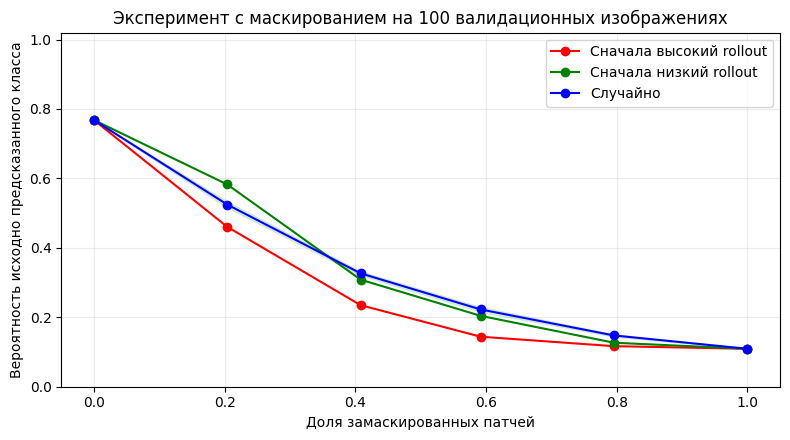

Сначала высокий rollout: AUC маскирования = 0.281
Сначала низкий rollout: AUC маскирования = 0.334
Случайно            : AUC маскирования = 0.333


In [39]:
model.eval()
with torch.no_grad():
    clean_logits, attention_maps = model(exp_x, return_attention=True)
    rollout_scores = attention_rollout(attention_maps)
del attention_maps
fixed_classes = clean_logits.argmax(dim=-1)
N = model.num_patches
mask_counts = np.unique(np.rint(np.linspace(0, N, 6)).astype(int))
fractions = mask_counts / N
high_order = rank_patches(rollout_scores, "high")
low_order = rank_patches(rollout_scores, "low")

@torch.no_grad()
def deletion_curve(ranking):
    values = []
    for count in mask_counts:
        masked = mask_patches(exp_x, ranking, int(count), model.patch_size)
        logits = model(masked)
        probabilities = logits.softmax(dim=-1).gather(1, fixed_classes[:, None]).squeeze(1)
        values.append(probabilities.cpu().numpy())
    return np.stack(values)    # (число долей маскирования, число изображений)

high_curve = deletion_curve(high_order)
low_curve = deletion_curve(low_order)
random_curves = []
for repeat in range(3):
    generator = torch.Generator().manual_seed(SEED + 100 + repeat)
    order = rank_patches(rollout_scores, "random", generator)
    random_curves.append(deletion_curve(order))
random_curves = np.stack(random_curves)  # (повторы, доли маскирования, изображения)
curve_means = {
    'Сначала высокий rollout': high_curve.mean(axis=1),
    'Сначала низкий rollout': low_curve.mean(axis=1),
    'Случайно': random_curves.mean(axis=(0, 2)),
}
random_std = random_curves.mean(axis=2).std(axis=0)

# При 0% и 100% входы всех стратегий одинаковы, поэтому результаты должны совпадать.
for curve in (low_curve, *random_curves):
    np.testing.assert_allclose(high_curve[[0, -1]], curve[[0, -1]], atol=1e-5, rtol=1e-4)
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['blue', 'green', 'red']
for name, values in curve_means.items():
    ax.plot(fractions, values, marker="o", label=name, c=colors[-1])
    colors.pop()
ax.fill_between(fractions, curve_means['Случайно'] - random_std,
                curve_means['Случайно'] + random_std, alpha=0.15, color="tab:green")
ax.set(xlabel='Доля замаскированных патчей', ylabel='Вероятность исходно предсказанного класса',
       title=f"Эксперимент с маскированием на {len(exp_x)} валидационных изображениях", ylim=(0, 1.02))
ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.show()

auc_results = {}
for name, values in curve_means.items():
    # Интегрирование методом трапеций: явная запись для совместимости с NumPy 1/2.
    area = float(np.sum((values[:-1] + values[1:]) * 0.5 * np.diff(fractions)))
    auc_results[name] = area
    print(f"{name:20s}: AUC маскирования = {area:.3f}")

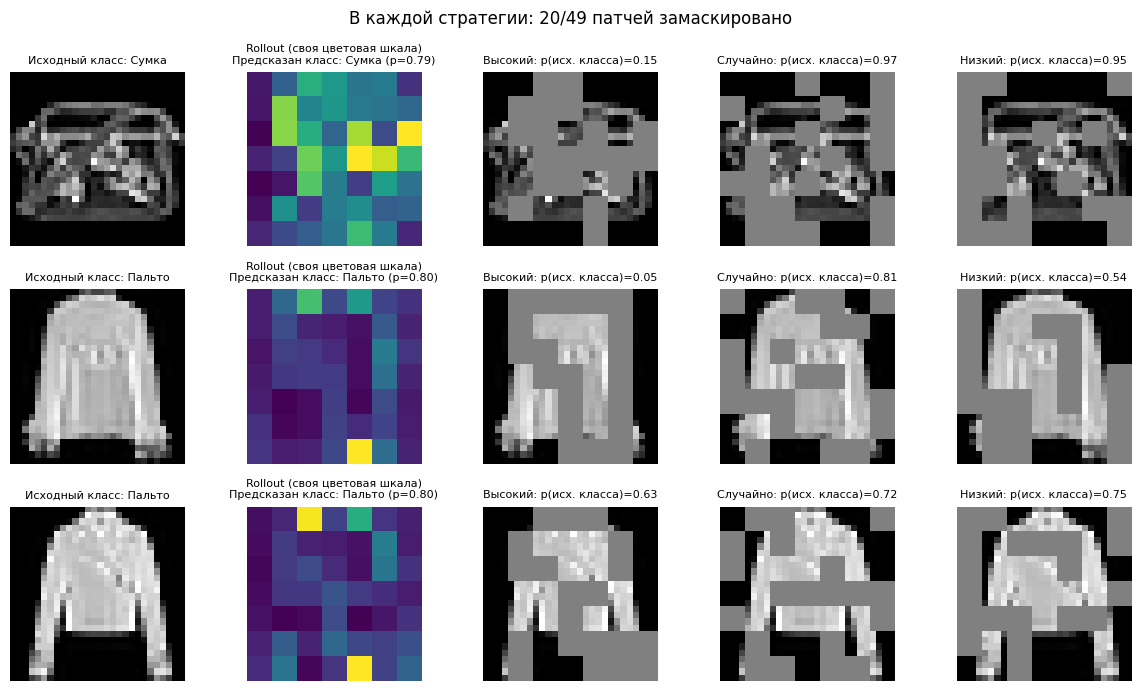

In [40]:
# Показываем первые три фиксированных примера, не отбирая удобные результаты.

# добавим также сами вероятности модели на незамаскированных патчах
with torch.no_grad():
    values, indices = model(exp_x[:3, ...]).softmax(-1).sort(-1, descending=True)
no_masked_probabilities = values[:, 0]
no_masked_pred_classes = [class_names[x] for x in indices[:, 0]]

count = int(round(0.4 * N))
random_order = rank_patches(rollout_scores, "random", torch.Generator().manual_seed(SEED + 100))
masked_versions = [mask_patches(exp_x, order, count, model.patch_size)
                   for order in (high_order, random_order, low_order)]
with torch.no_grad():
    masked_probabilities = [model(batch).softmax(-1).gather(1, fixed_classes[:, None]).squeeze(1)
                            for batch in masked_versions]
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
grid = IMAGE_SIZE // model.patch_size
for i in range(3):
    axes[i, 0].imshow((exp_x[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Исходный класс: {class_names[int(fixed_classes[i])]}", fontsize=8)
    axes[i, 1].imshow(rollout_scores[i].reshape(grid, grid).cpu(), cmap="viridis")
    axes[i, 1].set_title(f'Rollout (своя цветовая шкала)\nПредсказан класс: {no_masked_pred_classes[i]} (p={float(no_masked_probabilities[i]):.2f})', fontsize=8)
    for j, name in enumerate(('Высокий', 'Случайно', 'Низкий')):
        axes[i, j+2].imshow((masked_versions[j][i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[i, j+2].set_title(f"{name}: p(исх. класса)={float(masked_probabilities[j][i]):.2f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"В каждой стратегии: {count}/{N} патчей замаскировано", fontsize=12)
plt.tight_layout(); plt.show()

### Обсуждение (150–250 слов) (2 балла)

1. У какой стратегии самая низкая AUC? Сохраняется ли порядок стратегий при разных долях маскирования?
2. Опишите одно показанное изображение, для которого ранжирование по rollout кажется полезным, и одно, для которого результат менее убедителен, если такое есть. Не придумывайте неудачный пример, если показанные изображения его не демонстрируют.
3. Почему при сравнении стратегий нужно фиксировать отслеживаемый класс, число маскируемых патчей, значение заполнения маски и сами изображения?
4. Приведите две причины, по которым этот эксперимент не доказывает, что rollout достоверно объясняет, «куда смотрит модель».

**Ваш ответ:**
1. У высокого rollout самая низкая метрика AUC = 0.281. Порядок стратегий не сохранился:
   - В первой половине графика high < random < low - здесь всё ок.
   - Во второй половине конце high < low < random.
2. В 1-м примере high rollout сильно снизил вероятность исходного класса, тогда как другие стратегии наоборот повысили вероятность.   
   Явно неудачного примера для high rollout нет.      
3. Если не зафиксировать одинаковыми указанные параметры, то сравнение не будет честным:
   - Класс: сравниваем деградацию одной и той же величины; если класс «плывёт» после маскирования, падения вероятностей несопоставимы между стратегиями;
   - Число маскируемых патчей: вероятность сильно зависит от доли маскирования, при разном числе кривые нельзя класть на одну ось;
   - Значение заполнения маски: разный fill задаёт разный сдвиг распределения входа, эффект смешается с эффектом выбора патчей;
   - Изображения: сложность примеров разная, иначе сравниваем стратегии на разных данных.   
4. Во-первых, rollout — это грубое приближение (усреднение голов и грубое моделирование сети через residuals).   
   Во-вторых, маски создают входы, не характерные для обучающего распределения, и падение вероятности может также отражать изменение логитов других классов или падение общего качества модели.

## 7. Эксперимент 3 — что дают патчи меньшего размера? (3 балла в сумме)

Тут мы сравним модели, обученные с разными размерами патчей: `P=4` и `P=7`. Мы будем использовать тот же датасет. Основная модель уже обучена, поэтому используем её повторно, а с нуля обучим только вторую модель — с `P=7`.

Оставим одинаковыми разбиение данных, размер батча, количество эпох, оптимизатор,  scheduler, размерность эмбеддингов, глубину и число голов. Так мы убедимся, что у двух моделей будет одинаковым число обработанных примеров и шагов оптимизатора, **но не время обучения**.

### 7.1 Оцениваем объём вычислений — TODO 8 (1 балл)

Вычислите количество патчей изображения $N=(H/P)^2$, общее число токенов $T=N+1$ и количество элементов матрицы оценок внимания **для одного изображения, одной головы и одного слоя**: $T^2$. Учитывайте CLS. Здесь считаются элементы матрицы, а не полное число операций.

In [41]:
def patch_statistics(image_size, patch_size):
    assert image_size % patch_size == 0
    # TODO 8: верните словарь с ключами "patches", "tokens", "attention_entries".
    N = (image_size // patch_size) ** 2
    T = N + 1
    return {
        "patches": N,
        "tokens": N + 1,
        "attention_entries": T**2
    }

Следующая ячейка содержит проверки вашей реализации.

In [42]:
OTHER_PATCH_SIZE = 7
assert patch_statistics(28, 4) == {"patches": 49, "tokens": 50, "attention_entries": 2500}
assert patch_statistics(28, 7) == {"patches": 16, "tokens": 17, "attention_entries": 289}
for p in (PATCH_SIZE, OTHER_PATCH_SIZE):
    print(f"P={p}:", patch_statistics(IMAGE_SIZE, p))
entry_ratio = (patch_statistics(IMAGE_SIZE, PATCH_SIZE)["attention_entries"] /
               patch_statistics(IMAGE_SIZE, OTHER_PATCH_SIZE)["attention_entries"])
print(f"Отношение числа элементов внимания P={PATCH_SIZE} / P={OTHER_PATCH_SIZE}: {entry_ratio:.2f}×")

P=4: {'patches': 49, 'tokens': 50, 'attention_entries': 2500}
P=7: {'patches': 16, 'tokens': 17, 'attention_entries': 289}
Отношение числа элементов внимания P=4 / P=7: 8.65×


**До обучения:** предположите, какая модель будет быстрее, какая может дать более высокое качество и совпадёт ли отношение времен работы двух моделей с отношением числа элементов матрицы внимания в них.

**Ваши предположения:**   
Быстрее будет обучаться P=7.  
Более хорошее качество даст P=4.   
Совпадёт в рамках погрешности.

Обучим модель с новым размером патча.

P=7 | параметров=605,066 | валидация до обучения: потери=2.339, доля верных ответов=7.5%
эпоха  1/8 | потери на обучении 1.463, доля верных 51.2% | потери на валидации 1.012, доля верных 66.8% | обучение 0.9с
эпоха  2/8 | потери на обучении 0.893, доля верных 70.6% | потери на валидации 0.720, доля верных 75.6% | обучение 0.9с
эпоха  3/8 | потери на обучении 0.701, доля верных 76.2% | потери на валидации 0.593, доля верных 79.3% | обучение 0.8с
эпоха  4/8 | потери на обучении 0.604, доля верных 79.1% | потери на валидации 0.560, доля верных 80.1% | обучение 0.8с
эпоха  5/8 | потери на обучении 0.534, доля верных 81.7% | потери на валидации 0.513, доля верных 81.8% | обучение 0.8с
эпоха  6/8 | потери на обучении 0.494, доля верных 82.6% | потери на валидации 0.533, доля верных 82.0% | обучение 0.8с
эпоха  7/8 | потери на обучении 0.466, доля верных 83.8% | потери на валидации 0.486, доля верных 82.8% | обучение 0.8с
эпоха  8/8 | потери на обучении 0.445, доля верных 84.7% | потери на ва

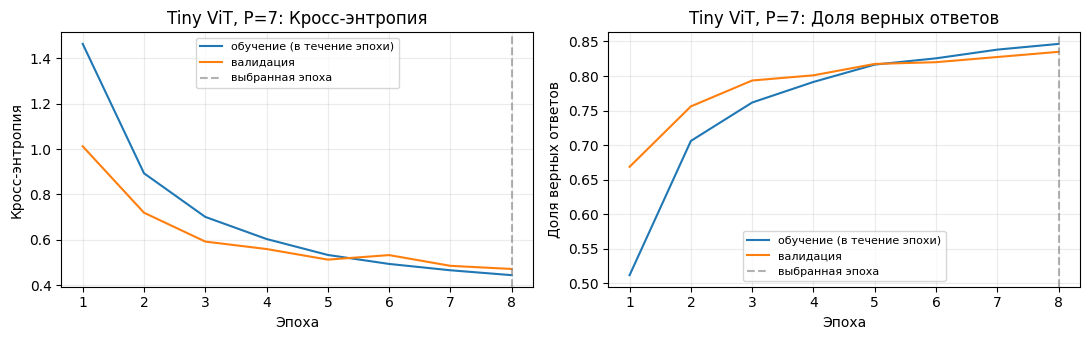

In [43]:
seed_everything(SEED)
other_model = TinyViT(**model_config(OTHER_PATCH_SIZE)).to(device)
other_result = fit_model(other_model)
plot_history(other_result, f"Tiny ViT, P={OTHER_PATCH_SIZE}")
model = main_result["model"]

Сравним результаты.

  P  токены    параметры     шаги    обуч., с кач. вал.  пот. вал.
  4      50      605,066      632         9.7     82.0%      0.518
  7      17      605,066      632         6.8     83.5%      0.472
Отношение измеренного времени обучения P=4 / P=7: 1.43×


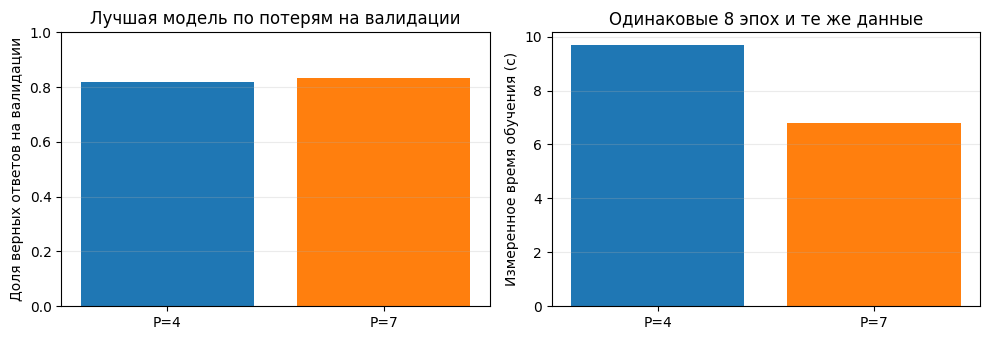

In [44]:
comparison = {PATCH_SIZE: main_result, OTHER_PATCH_SIZE: other_result}
print(f"{'P':>3} {'токены':>7} {'параметры':>12} {'шаги':>8} {'обуч., с':>11} {'кач. вал.':>9} {'пот. вал.':>10}")
for p, result in comparison.items():
    stats = patch_statistics(IMAGE_SIZE, p)
    print(f"{p:3d} {stats['tokens']:7d} {result['parameters']:12,d} {result['updates']:8d} "
          f"{result['train_seconds']:11.1f} {result['val_acc']:9.1%} {result['val_loss']:10.3f}")
assert main_result["updates"] == other_result["updates"]
print(f"Отношение измеренного времени обучения P={PATCH_SIZE} / P={OTHER_PATCH_SIZE}: "
      f"{main_result['train_seconds'] / other_result['train_seconds']:.2f}×")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
names = [f"P={p}" for p in comparison]
axes[0].bar(names, [r["val_acc"] for r in comparison.values()], color=["tab:blue", "tab:orange"])
axes[0].set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Лучшая модель по потерям на валидации')
axes[1].bar(names, [r["train_seconds"] for r in comparison.values()], color=["tab:blue", "tab:orange"])
axes[1].set(ylabel='Измеренное время обучения (с)', title=f"Одинаковые {EPOCHS} эпох и те же данные")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### Обсуждение (150–250 слов) (2 балла)

1. Приведите для обеих моделей долю верных ответов на валидации, время обучения, количество токенов и число параметров.
2. Объясните, почему отношение числа элементов матрицы внимания отличается от отношения времени работы.
3. Оправдала ли более мелкая сетка патчей дополнительные затраты при фиксированном числе эпох? Укажите свой критерий.
4. Какие выводы можно и нельзя сделать по одному seed на этом датасете? Ответило бы сравнение при одинаковом времени обучения на тот же вопрос?

**Ваш ответ:**

1. Рез-ты обучений:
   | Модель | Val Accuracy | Время обучения | Полное время | Кол-во токенов модели | Число параметров |
   |--- | --- | --- | --- | --- | --- |
   | P=4 | 80.7% | 9.7с | 10.4с | 50 | 605066 |
   | P=7 | **83.5%** | **6.8с** | **7.3с** | 17 | 605066 |
2. Отношение числа элементов внимания P=4 / P=7: 8.65x. Отношение времени полной работы P=4 / P=7: 1.42x. Они между собой отличаются, т.к. архитектура модели состоит не только из матрицы внимания, но и из других слоев, которые влияют на время работы: свёртки, MLP, нормализация. Атеншн имеет асимптотику $O(T^2 \cdot d)$ ,а MLP $O(T \cdot d^2)$ и при небольших T<=50 MLP вносит значимый вклад. Плюс есть накладные расходы по типу загрузки данных, kernel launch, оптимизатор и пр. Для более точного ответа, какой слой сколько отрабатывает, нужно делать профилировку.
3. Мелкая сетка себя P=4 не оправдала. Критерий - прирост val_accuracy покрывает рост стоимости. Мелкая сетка обучается дольше, а качество даёт меньше.
4. Разрыв между подходами заметный (80.7% vs 83.5%), но утверждать одназночное превосходство P=7 нельзя: нужны несколько сидов и доверительные интервалы. 
   Сравнение при равном времени обучения отвечает на другой вопрос — «что лучше при фиксированном бюджете вычислений». Судя по графикам при равном бюджете времени выиграл бы, вероятно, P=7: он уже при равных эпохах и быстрее и точнее.

## 8. Итоговая оценка на отложенной тестовой выборке

Сначала завершите эксперименты и зафиксируйте все решения. Выберите один из двух размеров патча по **функции потерь на валидации** и один раз оцените соответствующее сохранённое состояние модели на официальной тестовой выборке. Не меняйте гиперпараметры на основе тестового результата. Если продолжите разработку, учитывайте, что тест уже был просмотрен, и укажите это в отчёте.

Матрица ошибок помогает увидеть, какие категории одежды модель путает. Она не участвует в выборе модели.

Выбрано P=7 по потерям на валидации
ТЕСТ | 10000 изображений | потери=0.491 | доля верных ответов=82.7%


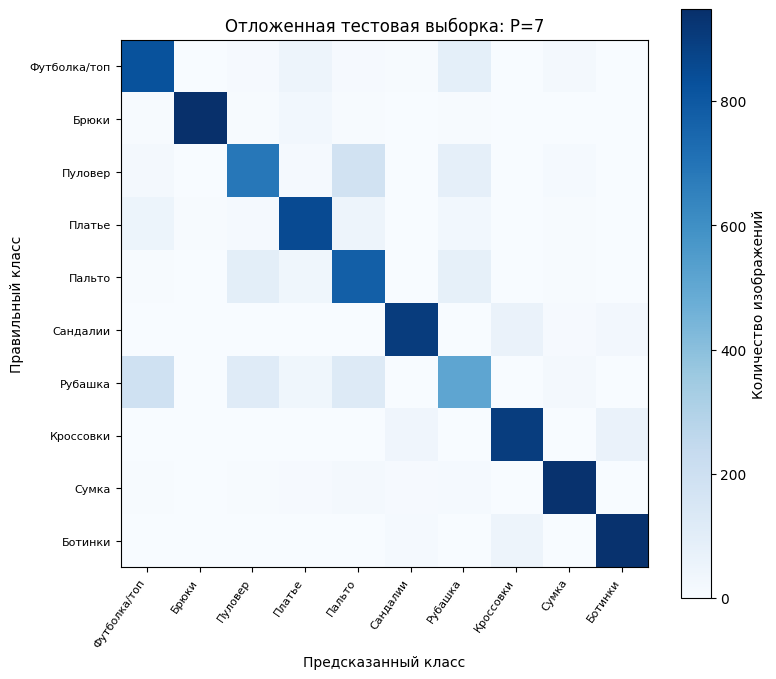

In [45]:
selected_patch_size = min(comparison, key=lambda p: comparison[p]["val_loss"])
selected_model = comparison[selected_patch_size]["model"]
test_metrics = evaluate(selected_model, make_loader(test_set))
print(f"Выбрано P={selected_patch_size} по потерям на валидации")
print(f"ТЕСТ | {len(test_set)} изображений | потери={test_metrics['loss']:.3f} | доля верных ответов={test_metrics['accuracy']:.1%}")

confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
selected_model.eval()
with torch.no_grad():
    for x, y in make_loader(test_set):
        prediction = selected_model(x.to(device)).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * NUM_CLASSES + prediction,
                                    minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES), labels=class_names, fontsize=8)
ax.set(xlabel='Предсказанный класс', ylabel='Правильный класс', title=f"Отложенная тестовая выборка: P={selected_patch_size}")
plt.colorbar(im, ax=ax, label='Количество изображений')
plt.tight_layout(); plt.show()

Поздравляем! Вы завершили домашнее задание =)

## Источники

- [Dosovitskiy et al. — An Image is Worth 16×16 Words](https://arxiv.org/abs/2010.11929)
- [Датасет Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)
- [PyTorch Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [Abnar & Zuidema — Quantifying Attention Flow in Transformers](https://aclanthology.org/2020.acl-main.385/)